<a href="https://colab.research.google.com/github/rinosetiyo/DataScience_ML/blob/main/house_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
# take dataset
from sklearn.datasets import fetch_california_housing

# make dataset to format dataframe
housing = fetch_california_housing(as_frame=True)

# change dataset to dataframe
df = housing.frame

# show data 5 above
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [33]:
# check data shape
df.shape

(20640, 9)

In [34]:
# check about columns
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

In [35]:
# check info data about data type and missing value
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [36]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [37]:
# # make folder to save dataset to our data file
# Path("data/raw").mkdir(parents=True, exist_ok=True)

# # save dataset
# df.to_csv("data/raw/california_housing.csv", index=False)

In [38]:
# check missing values
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


In [39]:
# check duplicate data
df.duplicated().sum()

np.int64(0)

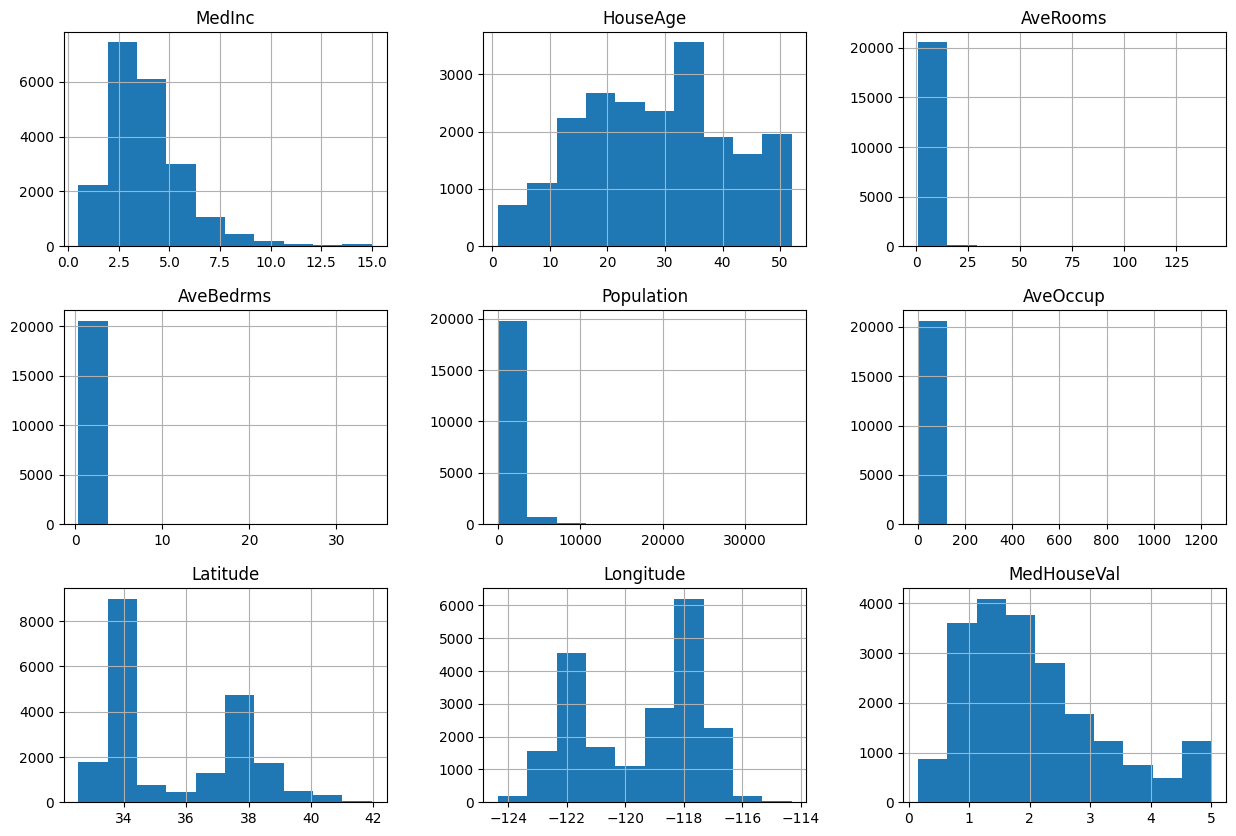

In [40]:
# check data distribution
import matplotlib.pyplot as plt
df.hist(figsize=(15, 10))

plt.show()

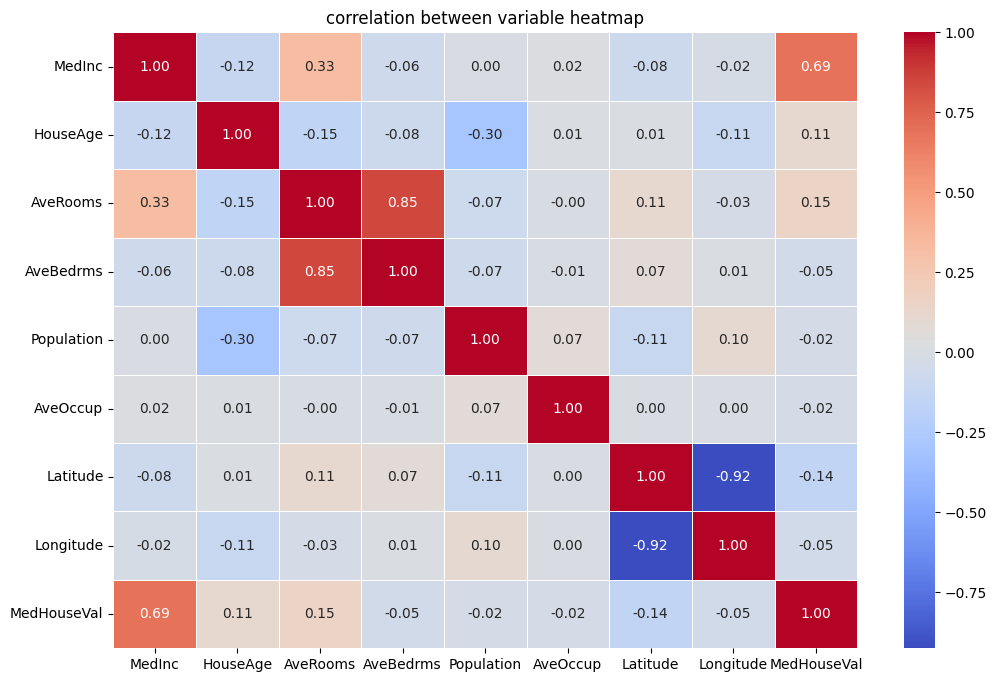

In [41]:
# check corelation between variable
import seaborn as sns

plt.figure(figsize=(12, 8))
correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5)

plt.title("correlation between variable heatmap")
plt.show()

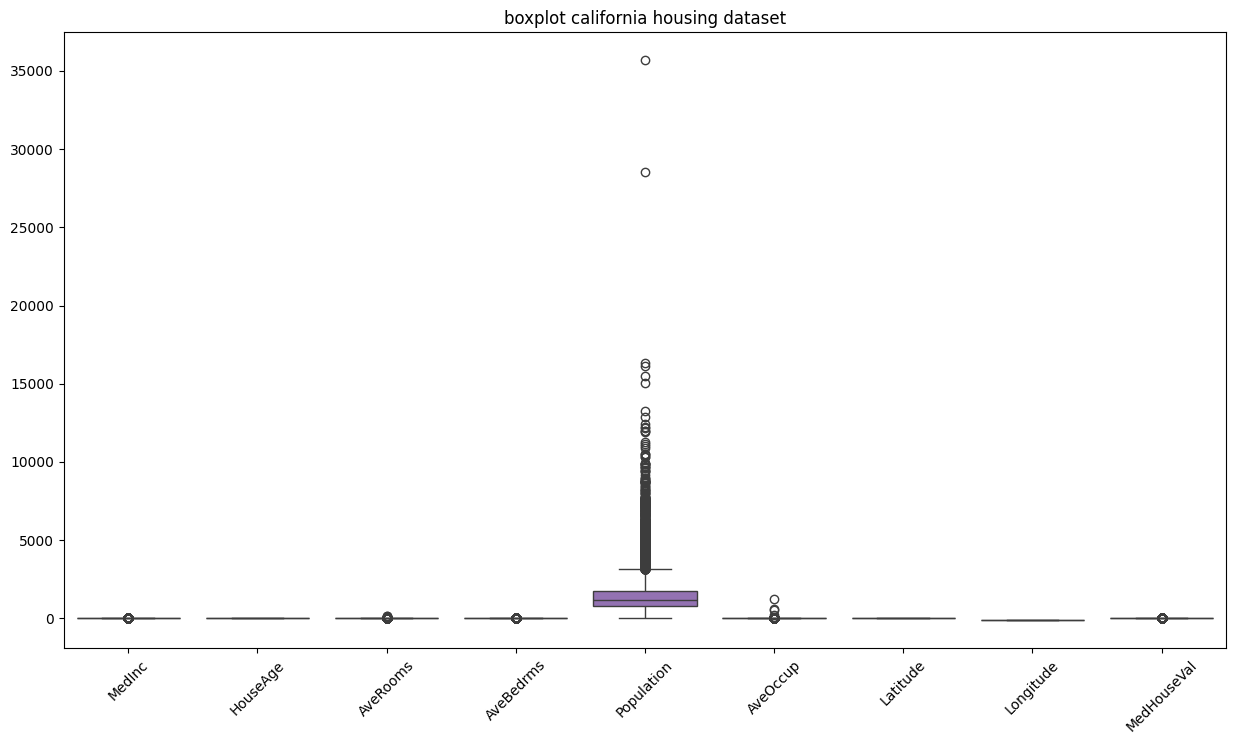

In [42]:
# identify outlier
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))
sns.boxplot(data=df)

plt.xticks(rotation=45)
plt.title("boxplot california housing dataset")
plt.show()

In [43]:
correlation["MedHouseVal"].sort_values(ascending=False)

,MedHouseVal
MedHouseVal,1.000000
MedInc,0.688075
AveRooms,0.151948
HouseAge,0.105623
AveOccup,-0.023737
Population,-0.024650
Longitude,-0.045967
AveBedrms,-0.046701
Latitude,-0.144160


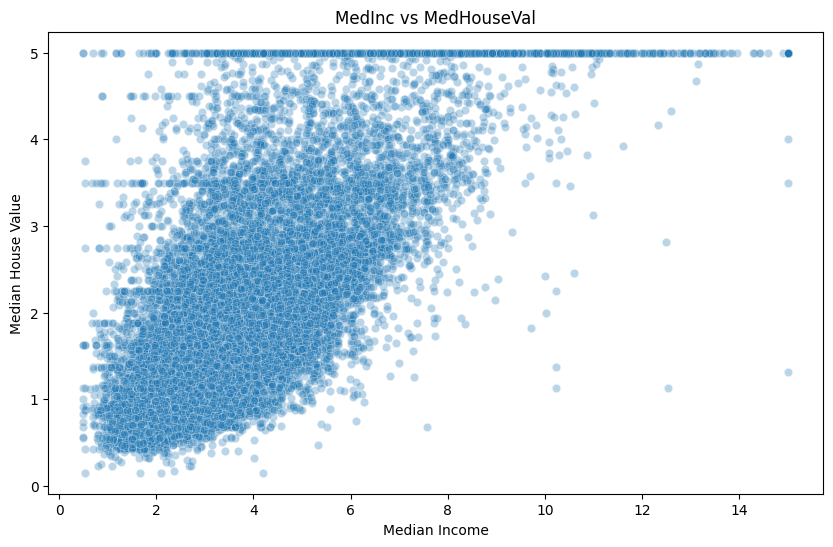

In [44]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="MedInc", y="MedHouseVal", alpha=0.3)

plt.title("MedInc vs MedHouseVal")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.show()

In [45]:
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

print('shape X:', X.shape)
print('shape y:', y.shape)
print('Features:', X.columns.tolist())
print('Target:', y.name)

shape X: (20640, 8)
shape y: (20640,)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: MedHouseVal


In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('shape X_train:', X_train.shape)
print('shape X_test:', X_test.shape)
print('shape y_train:', y_train.shape)
print('shape y_test:', y_test.shape)

shape X_train: (16512, 8)
shape X_test: (4128, 8)
shape y_train: (16512,)
shape y_test: (4128,)


In [47]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('shape X_train:', X_train_scaled.shape)
print('shape X_test:', X_test_scaled.shape)
print("mean training:", X_train_scaled.mean(axis=0))
print("std training:", X_train_scaled.std(axis=0))

shape X_train: (16512, 8)
shape X_test: (4128, 8)
mean training: [-6.41175313e-17 -1.67824411e-17  1.79012705e-16 -6.89371041e-16
  0.00000000e+00  1.03276560e-17  3.38574991e-15  1.77678716e-15]
std training: [1. 1. 1. 1. 1. 1. 1. 1.]


In [48]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

print('result of prediction:', y_pred[:10])
print('real result', y_test.iloc[:10].values)
print('intercept:', model.intercept_)
print('coefficient:', model.coef_)

result of prediction: [0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]
real result [0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]
intercept: 2.071946937378881
coefficient: [ 0.85438303  0.12254624 -0.29441013  0.33925949 -0.00230772 -0.0408291
 -0.89692888 -0.86984178]


In [49]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print('MAE:', mae)
print('MSE:', mse)
print('RMSE:', rmse)

MAE: 0.5332001304956565
MSE: 0.555891598695244
RMSE: 0.7455813830127761


In [50]:
y_train_pred = model.predict(X_train_scaled)

train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_pred)

print('MAE train:', train_mae)
print('MAE test:', test_mae)

MAE train: 0.5286283596581935
MAE test: 0.5332001304956565


In [51]:
import pandas as pd

comparison = pd.DataFrame(
    {
        "actual": y_test.iloc[:10].values,
        "predicted": y_pred[:10]
    }
)

comparison['Error'] = (
    comparison['actual'] - comparison['predicted']
)

print(comparison)

    actual  predicted     Error
0  0.47700   0.719123 -0.242123
1  0.45800   1.764017 -1.306017
2  5.00001   2.709659  2.290351
3  2.18600   2.838926 -0.652926
4  2.78000   2.604657  0.175343
5  1.58700   2.011754 -0.424754
6  1.98200   2.645500 -0.663500
7  1.57500   2.168755 -0.593755
8  3.40000   2.740746  0.659254
9  4.46600   3.915615  0.550385


In [52]:
# decision tree regressor model
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(random_state=42)
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)
tree_train_pred = tree_model.predict(X_train)

tree_train_mae = mean_absolute_error(y_train, tree_train_pred)
tree_test_mae = mean_absolute_error(y_test, tree_pred)

tree_train_rmse = np.sqrt(mean_squared_error(y_train, tree_train_pred))
tree_test_rmse = np.sqrt(mean_squared_error(y_test, tree_pred))

print('MAE train:', tree_train_mae)
print('MAE test:', tree_test_mae)
print('RMSE train:', tree_train_rmse)
print('RMSE test:', tree_test_rmse)

MAE train: 4.5936553441370335e-17
MAE test: 0.45467918846899225
RMSE train: 3.218325866275131e-16
RMSE test: 0.7037294974840077


In [53]:
comparison_models = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "MAE Train": [train_mae, tree_train_mae],
    "MAE Test": [test_mae, tree_test_mae],
    "RMSE Train": [rmse, tree_train_rmse],
    "RMSE Test": [rmse, tree_test_rmse]
})

print(comparison_models)

               Model     MAE Train  MAE Test    RMSE Train  RMSE Test
0  Linear Regression  5.286284e-01  0.533200  7.455814e-01   0.745581
1      Decision Tree  4.593655e-17  0.454679  3.218326e-16   0.703729


In [54]:
tree_model_limited = DecisionTreeRegressor(max_depth=10, random_state=42)
tree_model_limited.fit(X_train, y_train)

limited_train_pred = tree_model_limited.predict(X_train)
limited_test_pred = tree_model_limited.predict(X_test)

limited_train_mae = mean_absolute_error(y_train, limited_train_pred)
limited_test_mae = mean_absolute_error(y_test, limited_test_pred)

limited_train_rmse = np.sqrt(mean_squared_error(y_train, limited_train_pred))
limited_test_rmse = np.sqrt(mean_squared_error(y_test, limited_test_pred))

print('MAE train:', limited_train_mae)
print('MAE test:', limited_test_mae)
print('RMSE train:', limited_train_rmse)
print('RMSE test:', limited_test_rmse)

MAE train: 0.3191957491376588
MAE test: 0.4332031802610876
RMSE train: 0.46996360625539524
RMSE test: 0.6445682261497634


In [55]:
# random forest regressor
# step 1 import library
from sklearn.ensemble import RandomForestRegressor

# step 2 make models
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# step 3 training
rf_model.fit(X_train, y_train)

# step 4 prediction
rf_train_pred = rf_model.predict(X_train)
rf_test_pred = rf_model.predict(X_test)

# step 5 evaluate
rf_train_mae = mean_absolute_error(y_train, rf_train_pred)
rf_test_mae = mean_absolute_error(y_test, rf_test_pred)

rf_train_rmse = np.sqrt(mean_squared_error(y_train, rf_train_pred))
rf_test_rmse = np.sqrt(mean_squared_error(y_test, rf_test_pred))

print('MAE train:', rf_train_mae)
print('MAE test:', rf_test_mae)
print('RMSE train:', rf_train_rmse)
print('RMSE test:', rf_test_rmse)

MAE train: 0.12205671543120195
MAE test: 0.32754256845930246
RMSE train: 0.18795619089802199
RMSE test: 0.5053399773665033


In [56]:
# comparasion models

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Decision Tree Limited Depth 10",
        "Random Forest"],
    "MAE Train": [
        train_mae,
        tree_train_mae,
        limited_train_mae,
        rf_train_mae],
    "MAE Test": [
        test_mae,
        tree_test_mae,
        limited_test_mae,
        rf_test_mae],
    "RMSE Train": [
        rmse,
        tree_train_rmse,
        limited_train_rmse,
        rf_train_rmse],
    "RMSE Test": [
        rmse,
        tree_test_rmse,
        limited_test_rmse,
        rf_test_rmse]
})

print(results.sort_values(by="MAE Test"))

                            Model     MAE Train  MAE Test    RMSE Train  \
3                   Random Forest  1.220567e-01  0.327543  1.879562e-01   
2  Decision Tree Limited Depth 10  3.191957e-01  0.433203  4.699636e-01   
1                   Decision Tree  4.593655e-17  0.454679  3.218326e-16   
0               Linear Regression  5.286284e-01  0.533200  7.455814e-01   

   RMSE Test  
3   0.505340  
2   0.644568  
1   0.703729  
0   0.745581  


In [57]:
# take feature importance from random forest
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(by="Importance", ascending=False)

print(feature_importance)

      Feature  Importance
0      MedInc    0.524871
5    AveOccup    0.138443
6    Latitude    0.088936
7   Longitude    0.088629
1    HouseAge    0.054593
2    AveRooms    0.044272
4  Population    0.030650
3   AveBedrms    0.029606


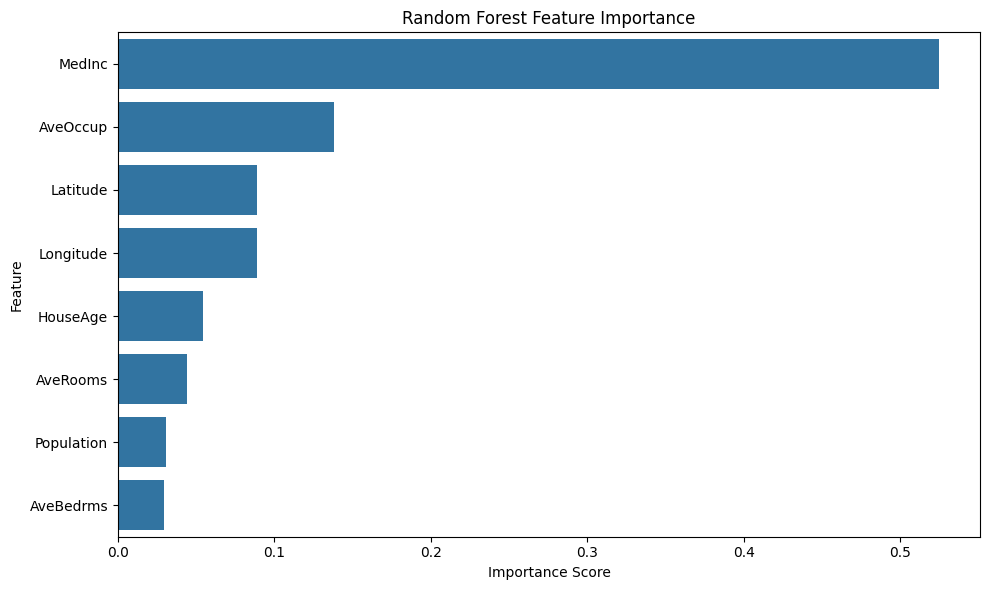

In [58]:
# make visualisation feature importance
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance
)

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [59]:
# permutation importance
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="neg_mean_absolute_error"
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": permutation_result.importances_mean
})

permutation_importance_df = permutation_importance_df.sort_values(
    by="Importance", ascending=False)

print(permutation_importance_df)

      Feature  Importance
0      MedInc    0.444976
6    Latitude    0.352063
7   Longitude    0.295595
5    AveOccup    0.159055
1    HouseAge    0.058334
2    AveRooms    0.035365
3   AveBedrms    0.008444
4  Population    0.007411


In [60]:
# hyperparameter tuning
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=4,
    n_jobs=-1
)

In [62]:
# use gridsearchcv
# step 1 import library
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

# step 2 make parameter combinations
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
}

# step 3 make gridsearchcv
grid_search = GridSearchCV(
    estimator= RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=3,
    n_jobs=-1,
    scoring='neg_mean_absolute_error',
    verbose=1
)

# step 4 training
grid_search.fit(X_train, y_train)

# step 5 best parameter
print("Best Parameters:", grid_search.best_params_)
print("Best CV MAE:", grid_search.best_score_)


Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best Parameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Best CV MAE: -0.3385773263055081


In [63]:
# hyperparameter tuning
best_model = grid_search.best_estimator_
print("Best Parameters:", best_model.get_params())
print(grid_search.best_params_)

# step 6 evaluation
best_test_pred = best_model.predict(X_test)

best_test_mae = mean_absolute_error(y_test, best_test_pred)
best_test_rmse = np.sqrt(mean_squared_error(y_test, best_test_pred))

print('Tuned MAE test:', best_test_mae)
print('Tuned RMSE test:', best_test_rmse)


Best Parameters: {'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 2, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 200, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
MAE test: 0.32599704472621915
RMSE test: 0.504018445179664


In [64]:
# compare random forest baseline and random forest tuned

model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest Baseline",
        "Random Forest Tuned"],
    "MAE Test": [
        rf_test_mae,
        best_test_mae],
    "RMSE Test": [
        rf_test_rmse,
        best_test_rmse]
})

print(model_comparison)

                    Model  MAE Test  RMSE Test
1     Random Forest Tuned  0.325997   0.504018
0  Random Forest Baseline  0.327543   0.505340


In [ ]:
# # model persistence
# import joblib
# joblib.dump(
#     best_model,
#     "california_housing_model.joblib")

# # if want use model in any projects or new notebook
# loaded_model = joblib.load(
#     "california_housing_model.joblib")

# # sample for using that model
# sample_prediction = loaded_model.predict(X_test[:5])
# print(sample_prediction)

# # make and use support detail information (artifact)
# model_artifact = {
#     "model": best_model,
#     "feature_names": X_train.columns.tolist(),
#     "target_name": "MedHouseVal"
# }

# joblib.dump(
#     model_artifact,
#     "california_housing_model.joblib"
# )

# # this is how to load
# loaded_model_artifact = joblib.load(
#     "california_housing_model.joblib"
# )

# loaded_model = loaded_model_artifact["model"]
# feature_names = loaded_model_artifact["feature_names"]
# target_name = loaded_model_artifact["target_name"]